# Crop Yield Prediction — Model Building

## 1. Introduction

In the previous notebook, we cleaned and preprocessed the crop yield dataset.

The cleaned dataset contains:

- Duplicate records removed
- Categorical columns encoded using one-hot encoding
- All features converted into numerical format
- No missing values

In this notebook, we build machine learning models to predict crop yield.

The target variable is:

`hg/ha_yield`

This is a **regression problem** because the target variable is a continuous numerical value.

## 1. Imports and Load Cleaned Dataset

In this section, we import the required Python libraries and load the cleaned dataset created in the previous notebook.

The cleaned dataset already contains:

- Duplicate rows removed
- Categorical columns encoded
- No missing values
- Numerical format suitable for machine learning

We also import helper functions from `utils.py` for model evaluation and visualization.

In [15]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import sys
import os

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import r2_score

# Ignore warning messages
warnings.filterwarnings("ignore")

# Add src folder path to access utils.py
sys.path.insert(0, os.path.abspath("../src"))

# Import custom utility functions
from utils import (
    evaluate_model,
    plot_predictions,
    plot_residuals,
    cross_validate_model,
    compare_models
)

# Display and visualization settings
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Load cleaned dataset
df = pd.read_csv("../data/crop_yield_cleaned.csv")

print("Cleaned dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

df.head()

Cleaned dataset loaded successfully!
Number of rows: 25932
Number of columns: 114


,Year,hg/ha_yield,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp,Area_Algeria,Area_Angola,Area_Argentina,Area_Armenia,Area_Australia,Area_Austria,Area_Azerbaijan,Area_Bahamas,Area_Bahrain,Area_Bangladesh,Area_Belarus,Area_Belgium,Area_Botswana,Area_Brazil,Area_Bulgaria,Area_Burkina Faso,Area_Burundi,Area_Cameroon,Area_Canada,Area_Central African Republic,Area_Chile,Area_Colombia,Area_Croatia,Area_Denmark,Area_Dominican Republic,Area_Ecuador,Area_Egypt,Area_El Salvador,Area_Eritrea,Area_Estonia,Area_Finland,Area_France,Area_Germany,Area_Ghana,Area_Greece,Area_Guatemala,Area_Guinea,Area_Guyana,Area_Haiti,Area_Honduras,Area_Hungary,Area_India,Area_Indonesia,Area_Iraq,Area_Ireland,Area_Italy,Area_Jamaica,Area_Japan,Area_Kazakhstan,Area_Kenya,Area_Latvia,Area_Lebanon,Area_Lesotho,Area_Libya,Area_Lithuania,Area_Madagascar,Area_Malawi,Area_Malaysia,Area_Mali,Area_Mauritania,Area_Mauritius,Area_Mexico,Area_Montenegro,Area_Morocco,Area_Mozambique,Area_Namibia,Area_Nepal,Area_Netherlands,Area_New Zealand,Area_Nicaragua,Area_Niger,Area_Norway,Area_Pakistan,Area_Papua New Guinea,Area_Peru,Area_Poland,Area_Portugal,Area_Qatar,Area_Romania,Area_Rwanda,Area_Saudi Arabia,Area_Senegal,Area_Slovenia,Area_South Africa,Area_Spain,Area_Sri Lanka,Area_Sudan,Area_Suriname,Area_Sweden,Area_Switzerland,Area_Tajikistan,Area_Thailand,Area_Tunisia,Area_Turkey,Area_Uganda,Area_Ukraine,Area_United Kingdom,Area_Uruguay,Area_Zambia,Area_Zimbabwe,Item_Maize,Item_Plantains and others,Item_Potatoes,"Item_Rice, paddy",Item_Sorghum,Item_Soybeans,Item_Sweet potatoes,Item_Wheat,Item_Yams
0,1990,36613,1485.0,121.0,16.37,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0
1,1990,66667,1485.0,121.0,16.37,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0
2,1990,23333,1485.0,121.0,16.37,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0
3,1990,12500,1485.0,121.0,16.37,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0
4,1990,7000,1485.0,121.0,16.37,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0


## 2. Prepare Features, Train-Test Split and Scaling

In this section, we prepare the dataset for machine learning.

We perform three main steps:

1. Separate the input features `X` and target variable `y`
2. Split the dataset into training and testing sets
3. Apply feature scaling using `StandardScaler`

The target variable is:

`hg/ha_yield`

We use an **80:20 train-test split**, where:

- 80% of the data is used for training
- 20% of the data is used for testing

Feature scaling is mainly needed for models such as Linear Regression, Ridge, Lasso, and KNN.  
Tree-based models such as Decision Tree, Random Forest, and Gradient Boosting do not strictly require scaling.

In [4]:
# Separate features and target variable

target_col = "hg/ha_yield"

X = df.drop(columns=[target_col])
y = df[target_col]

print("Feature and target separation completed.")
print("Number of features:", X.shape[1])
print("Number of target values:", y.shape[0])

print("\nTarget Variable Summary")
print("-" * 40)
display(y.describe().round(2))

Feature and target separation completed.
Number of features: 113
Number of target values: 25932

Target Variable Summary
----------------------------------------


count     25932.00
mean      76978.13
std       84647.61
min          50.00
25%       19996.00
50%       39530.00
75%      104168.00
max      501412.00
Name: hg/ha_yield, dtype: float64

In [7]:
# Prepare features, train-test split, and scaling

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Load cleaned dataset
df = pd.read_csv("../data/crop_yield_cleaned.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

# Separate features and target
target_col = "hg/ha_yield"

X = df.drop(columns=[target_col])
y = df[target_col]

print("\nFeature and target separation completed.")
print("X shape:", X.shape)
print("y shape:", y.shape)

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("\nTrain-test split completed.")
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

# Feature scaling
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\nFeature scaling completed successfully.")
print("X_train_scaled shape:", X_train_scaled.shape)
print("X_test_scaled shape:", X_test_scaled.shape)

Dataset loaded successfully!
Dataset shape: (25932, 114)

Feature and target separation completed.
X shape: (25932, 113)
y shape: (25932,)

Train-test split completed.
X_train shape: (20745, 113)
X_test shape: (5187, 113)
y_train shape: (20745,)
y_test shape: (5187,)

Feature scaling completed successfully.
X_train_scaled shape: (20745, 113)
X_test_scaled shape: (5187, 113)


### Preparation Summary

The dataset is now ready for model training.

- The cleaned dataset contains **113 input features**.
- The target variable is **`hg/ha_yield`**.
- The data was split into training and testing sets using an 80:20 ratio.
- Feature scaling was applied after the train-test split to avoid data leakage.
- Scaled data will be used for scale-sensitive models.
- Unscaled data will be used for tree-based models.

## 3. Train Regression Models

In this section, we train five regression models to predict crop yield.

The models used are:

- Linear Regression
- Decision Tree Regressor
- Random Forest Regressor
- K-Nearest Neighbors Regressor
- Gradient Boosting Regressor

Scaled data is used for:

- Linear Regression
- K-Nearest Neighbors

Unscaled data is used for:

- Decision Tree
- Random Forest
- Gradient Boosting

Each model is evaluated using:

- MAE
- RMSE
- R² Score
- MAPE

In [3]:
# Create empty containers to store model results and trained models

results = []
models = {}

### 3a. Linear Regression

Linear Regression is used as the baseline model for this project.

It tries to find a linear relationship between the input features and the target variable `hg/ha_yield`.

Since Linear Regression is sensitive to feature scale, we use the scaled training and testing data.


  Linear Regression
  MAE   : 29920.7419
  RMSE  : 42681.5235
  R2    : 0.7487
  MAPE  : 0.8992


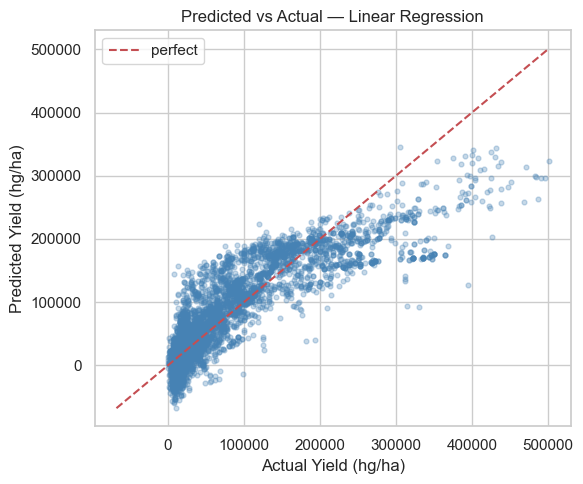

In [4]:
# Train Linear Regression model

linear_model = LinearRegression()

# Train using scaled data
linear_model.fit(X_train_scaled, y_train)

# Predict on scaled test data
linear_pred = linear_model.predict(X_test_scaled)

# Evaluate model
linear_result = evaluate_model(
    "Linear Regression",
    y_test,
    linear_pred
)

results.append(linear_result)

# Store trained model
models["Linear Regression"] = ("scaled", linear_model)

# Plot actual vs predicted values
plot_predictions(
    y_test,
    linear_pred,
    "Linear Regression"
)

plt.show()

### 3b. Decision Tree Regressor

Decision Tree Regressor is a tree-based machine learning model.

It splits the dataset into smaller groups based on feature values and predicts crop yield using decision rules.

Decision Trees can capture non-linear patterns better than Linear Regression.

Since Decision Tree is a tree-based model, we use the original unscaled training and testing data.### 3d. Decision Tree


  Decision Tree
  MAE   : 14352.6533
  RMSE  : 25653.0769
  R2    : 0.9092
  MAPE  : 0.3822


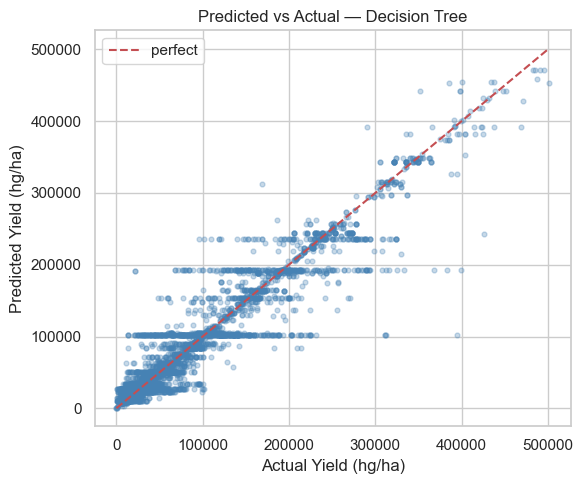

In [12]:
# Train Decision Tree Regressor model

decision_tree_model = DecisionTreeRegressor(
    max_depth=10,
    random_state=42
)

# Train using unscaled data
decision_tree_model.fit(X_train, y_train)

# Predict on test data
decision_tree_pred = decision_tree_model.predict(X_test)

# Evaluate model
decision_tree_result = evaluate_model(
    "Decision Tree",
    y_test,
    decision_tree_pred
)

results.append(decision_tree_result)

# Store trained model
models["Decision Tree"] = ("raw", decision_tree_model)

# Plot actual vs predicted values
plot_predictions(
    y_test,
    decision_tree_pred,
    "Decision Tree"
)

plt.show()

#### Decision Tree Observation

The Decision Tree model performs better than Linear Regression.

The R² score is higher, which means the model explains more variation in crop yield.

The prediction plot shows that many predictions are closer to the perfect prediction line compared to Linear Regression.

This suggests that crop yield has non-linear patterns that a tree-based model can capture better.

### 3c. Random Forest Regressor

Random Forest Regressor is an ensemble learning model.

It builds multiple decision trees and combines their predictions to produce a more accurate and stable result.

Random Forest usually performs better than a single Decision Tree because it reduces overfitting and captures complex patterns in the dataset.

Since Random Forest is a tree-based model, we use the original unscaled training and testing data.


  Random Forest
  MAE   : 3981.9541
  RMSE  : 10516.8967
  R2    : 0.9847
  MAPE  : 0.0858


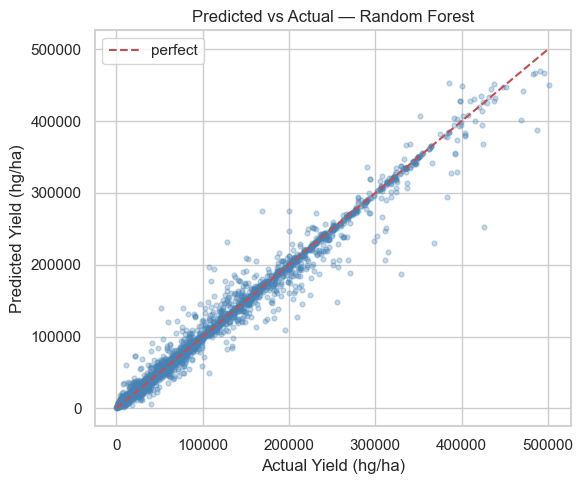

In [13]:
# Train Random Forest Regressor model

random_forest_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

# Train using unscaled data
random_forest_model.fit(X_train, y_train)

# Predict on test data
random_forest_pred = random_forest_model.predict(X_test)

# Evaluate model
random_forest_result = evaluate_model(
    "Random Forest",
    y_test,
    random_forest_pred
)

results.append(random_forest_result)

# Store trained model
models["Random Forest"] = ("raw", random_forest_model)

# Plot actual vs predicted values
plot_predictions(
    y_test,
    random_forest_pred,
    "Random Forest"
)

plt.show()

#### Random Forest Observation

The Random Forest model gives a very strong performance.

The R² score is much higher than Linear Regression and Decision Tree, showing that the model explains most of the variation in crop yield.

The prediction plot shows that most points are close to the perfect prediction line.

This indicates that Random Forest is able to capture complex non-linear patterns in the crop yield dataset.

### 3d. K-Nearest Neighbors Regressor

K-Nearest Neighbors Regressor predicts crop yield by looking at the most similar records in the training data.

The value of **K** decides how many nearby records are used for prediction.

In this section, we test different K values and select the best one based on the R² score.

Since KNN is distance-based, we use the scaled training and testing data.

Best K value: 3
Best R² score: 0.9852


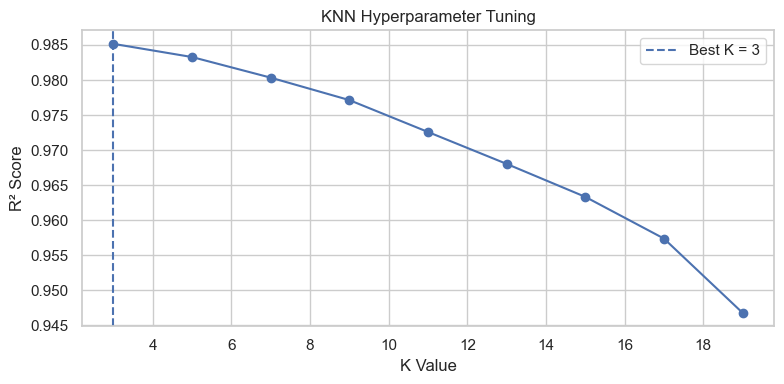

In [16]:
# Find the best K value for KNN Regressor

k_range = range(3, 21, 2)
k_scores = []

for k in k_range:
    knn_temp = KNeighborsRegressor(
        n_neighbors=k,
        n_jobs=-1
    )
    
    knn_temp.fit(X_train_scaled, y_train)
    knn_temp_pred = knn_temp.predict(X_test_scaled)
    
    score = r2_score(y_test, knn_temp_pred)
    k_scores.append(score)

# Select best K
best_k = list(k_range)[np.argmax(k_scores)]

print("Best K value:", best_k)
print("Best R² score:", round(max(k_scores), 4))

# Plot K optimization results
plt.figure(figsize=(8, 4))

plt.plot(
    list(k_range),
    k_scores,
    marker="o"
)

plt.axvline(
    best_k,
    linestyle="--",
    label=f"Best K = {best_k}"
)

plt.title("KNN Hyperparameter Tuning")
plt.xlabel("K Value")
plt.ylabel("R² Score")
plt.legend()
plt.tight_layout()
plt.show()


  KNN (K=3)
  MAE   : 4398.3175
  RMSE  : 10372.8742
  R2    : 0.9852
  MAPE  : 0.0869


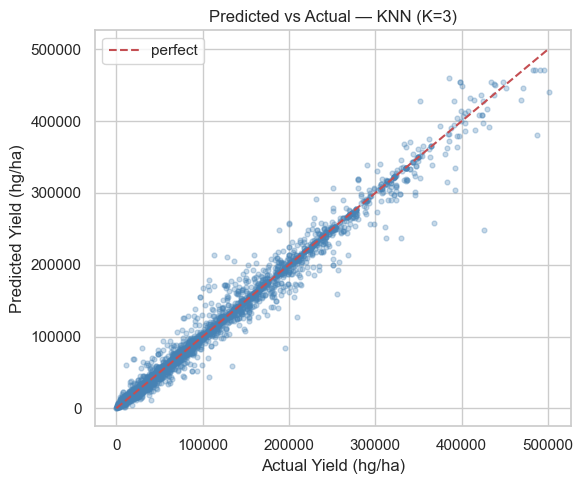

In [17]:
# Train final KNN model using best K value

knn_model = KNeighborsRegressor(
    n_neighbors=best_k,
    n_jobs=-1
)

# Train using scaled data
knn_model.fit(X_train_scaled, y_train)

# Predict on scaled test data
knn_pred = knn_model.predict(X_test_scaled)

# Create model name
knn_model_name = f"KNN (K={best_k})"

# Evaluate model
knn_result = evaluate_model(
    knn_model_name,
    y_test,
    knn_pred
)

results.append(knn_result)

# Store trained model
models[knn_model_name] = ("scaled", knn_model)

# Plot actual vs predicted values
plot_predictions(
    y_test,
    knn_pred,
    knn_model_name
)

plt.show()

#### KNN Observation

The KNN model performs very well after selecting the best K value.

The K optimization graph shows how model performance changes when different K values are used.

A smaller K value gives the best result in this dataset, meaning nearby records are highly useful for predicting crop yield.

Since KNN depends on distance calculations, feature scaling was important before training this model.

### 3e. Gradient Boosting Regressor

Gradient Boosting Regressor is an ensemble model that builds trees sequentially.

Each new tree tries to correct the errors made by the previous trees.

This model can capture non-linear patterns, but it may require careful tuning to achieve the best performance.

Since Gradient Boosting is a tree-based model, we use the original unscaled training and testing data.


  Gradient Boosting
  MAE   : 21675.4853
  RMSE  : 35144.7027
  R2    : 0.8296
  MAPE  : 0.5240


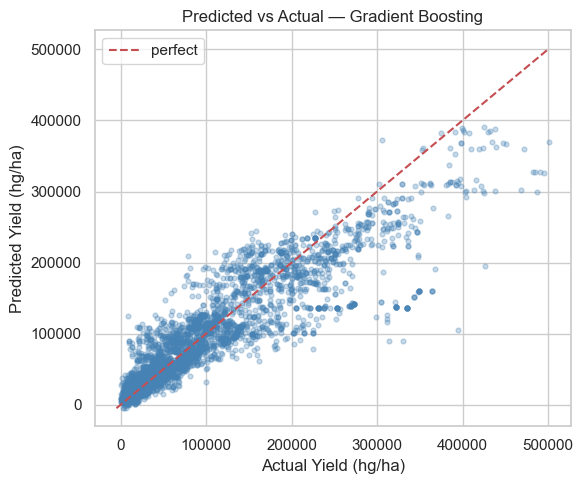

In [18]:
# Train Gradient Boosting Regressor model

gradient_boosting_model = GradientBoostingRegressor(
    n_estimators=200,
    random_state=42
)

# Train using unscaled data
gradient_boosting_model.fit(X_train, y_train)

# Predict on test data
gradient_boosting_pred = gradient_boosting_model.predict(X_test)

# Evaluate model
gradient_boosting_result = evaluate_model(
    "Gradient Boosting",
    y_test,
    gradient_boosting_pred
)

results.append(gradient_boosting_result)

# Store trained model
models["Gradient Boosting"] = ("raw", gradient_boosting_model)

# Plot actual vs predicted values
plot_predictions(
    y_test,
    gradient_boosting_pred,
    "Gradient Boosting"
)

plt.show()

#### Gradient Boosting Observation

The Gradient Boosting model performs better than Linear Regression, but it does not perform as well as Random Forest or KNN in this project.

The R² score shows that the model captures some non-linear patterns in the dataset.

However, the prediction plot shows that the model still struggles with some high crop yield values.

This suggests that Gradient Boosting may need further hyperparameter tuning to improve performance.

## 4. Model Comparison

In this section, we compare the performance of all trained regression models.

The models compared are:

- Linear Regression
- Decision Tree Regressor
- Random Forest Regressor
- K-Nearest Neighbors Regressor
- Gradient Boosting Regressor

The models are compared using:

- MAE
- RMSE
- R² Score
- MAPE

For this project, **R² Score** is the main comparison metric because it shows how well the model explains crop yield variation.

A higher R² Score and lower error values indicate better model performance.

In [19]:
# Compare trained model performance

comparison = compare_models(results)

# Remove Ridge and Lasso if they were previously run
comparison = comparison[
    ~comparison["Model"].isin(["Ridge", "Lasso", "Ridge Regression", "Lasso Regression"])
].reset_index(drop=True)

comparison

,Model,MAE,RMSE,R2,MAPE
0,KNN (K=3),4398.317525,10372.874161,0.985155,0.086896
1,Random Forest,3981.954058,10516.896679,0.984740,0.085843
2,Decision Tree,14352.653307,25653.076904,0.909204,0.382185
3,Decision Tree,14352.653307,25653.076904,0.909204,0.382185
4,Gradient Boosting,21675.485275,35144.702651,0.829585,0.524024
5,Linear Regression,29920.741936,42681.523481,0.748656,0.899238


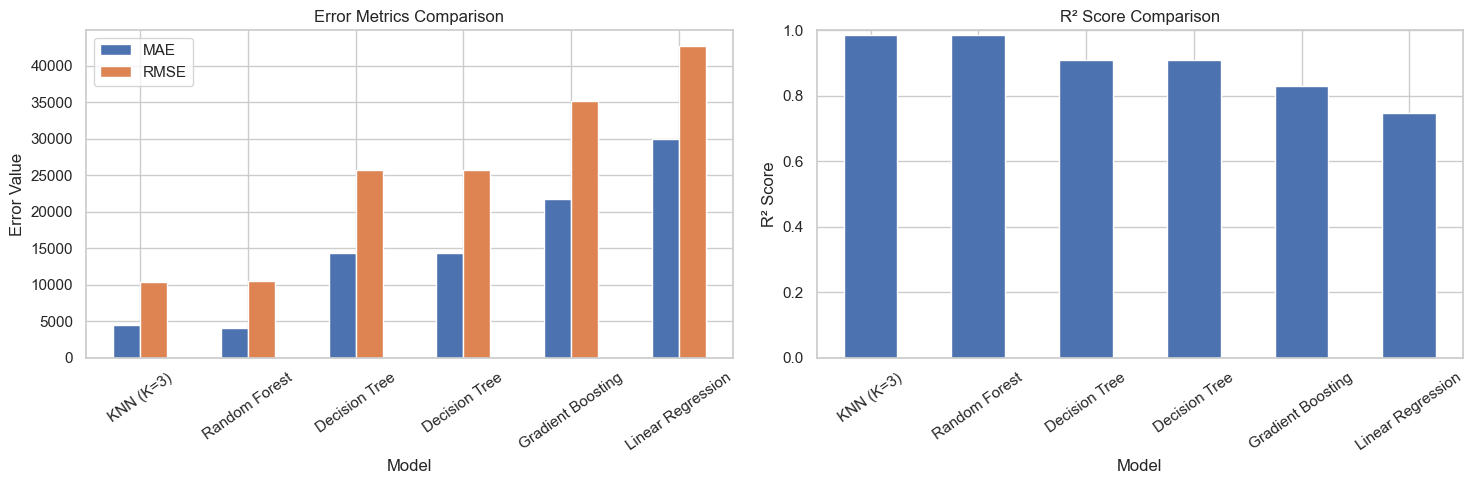

In [20]:
# Visualize model comparison

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Error metrics comparison
comparison.set_index("Model")[["MAE", "RMSE"]].plot(
    kind="bar",
    ax=axes[0]
)

axes[0].set_title("Error Metrics Comparison")
axes[0].set_xlabel("Model")
axes[0].set_ylabel("Error Value")
axes[0].tick_params(axis="x", rotation=35)

# R2 score comparison
comparison.set_index("Model")["R2"].plot(
    kind="bar",
    ax=axes[1]
)

axes[1].set_title("R² Score Comparison")
axes[1].set_xlabel("Model")
axes[1].set_ylabel("R² Score")
axes[1].tick_params(axis="x", rotation=35)
axes[1].set_ylim(0, 1)

plt.tight_layout()
plt.show()

### Model Comparison Observations

From the model comparison:

- KNN and Random Forest achieved the highest R² scores.
- Random Forest has the lowest MAE, while KNN has a slightly higher R² score.
- Decision Tree performs better than Linear Regression but lower than Random Forest and KNN.
- Gradient Boosting performs better than Linear Regression but weaker than Decision Tree, Random Forest, and KNN.
- Linear Regression has the weakest performance because crop yield relationships are not purely linear.

Overall, Random Forest and KNN are the strongest models in this project.

## 5. Feature Importances — Tree-Based Models

Tree-based models can show which features are most important for prediction using `feature_importances_`.

In this section, we compare feature importance from:

- Random Forest Regressor
- Gradient Boosting Regressor

Feature importance helps us understand which input variables have the strongest effect on crop yield prediction.

Since the dataset contains one-hot encoded columns, important features may include both original numerical columns and encoded crop/country columns.

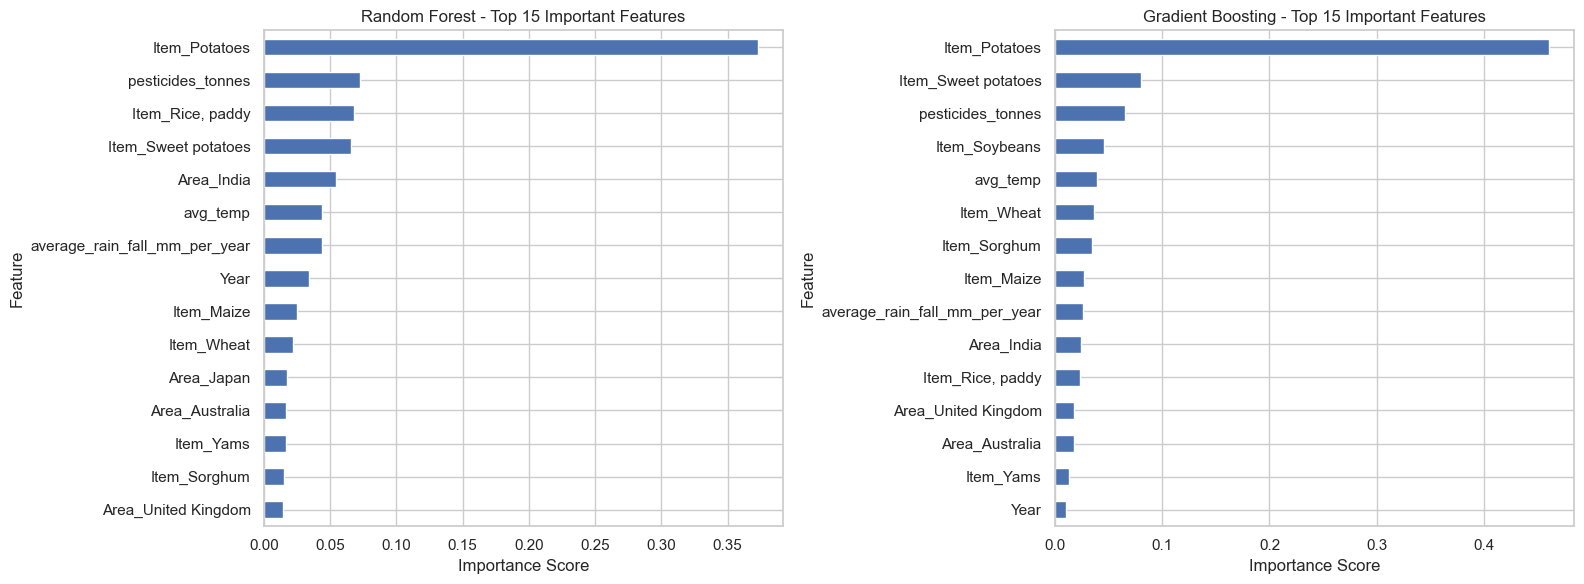

In [21]:
# Feature importance analysis for tree-based models

tree_models = {
    "Random Forest": random_forest_model,
    "Gradient Boosting": gradient_boosting_model
}

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, (model_name, model) in zip(axes, tree_models.items()):
    
    # Create feature importance series
    feature_importance = pd.Series(
        model.feature_importances_,
        index=X.columns
    ).sort_values(ascending=False).head(15)
    
    # Plot top 15 features
    feature_importance.sort_values().plot(
        kind="barh",
        ax=ax
    )
    
    ax.set_title(f"{model_name} - Top 15 Important Features")
    ax.set_xlabel("Importance Score")
    ax.set_ylabel("Feature")

plt.tight_layout()
plt.show()

## 6. 5-Fold Cross-Validation

Cross-validation gives a more reliable estimate of model performance than using only one train-test split.

In this section, we apply **5-fold cross-validation** to the selected regression models:

- Linear Regression
- Decision Tree
- Random Forest
- KNN
- Gradient Boosting

For Linear Regression and KNN, scaling is applied using a pipeline because these models are sensitive to feature scale.

Tree-based models are evaluated using the original unscaled data.

In [22]:
# 5-fold cross-validation for selected models

from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score

cv_models = {
    "Linear Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),
    
    "Decision Tree": DecisionTreeRegressor(
        max_depth=10,
        random_state=42
    ),
    
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),
    
    f"KNN (K={best_k})": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsRegressor(
            n_neighbors=best_k,
            n_jobs=-1
        ))
    ]),
    
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=200,
        random_state=42
    )
}

cv_scores = {}

for model_name, model in cv_models.items():
    
    scores = cross_val_score(
        model,
        X,
        y,
        cv=5,
        scoring="r2",
        n_jobs=-1
    )
    
    cv_scores[model_name] = scores
    
    print(f"{model_name:25s} Mean R² = {scores.mean():.4f} (+/- {scores.std():.4f})")

Linear Regression         Mean R² = 0.5639 (+/- 0.1007)
Decision Tree             Mean R² = 0.5923 (+/- 0.1194)
Random Forest             Mean R² = 0.6793 (+/- 0.0975)
KNN (K=3)                 Mean R² = 0.3729 (+/- 0.2587)
Gradient Boosting         Mean R² = 0.6439 (+/- 0.1021)


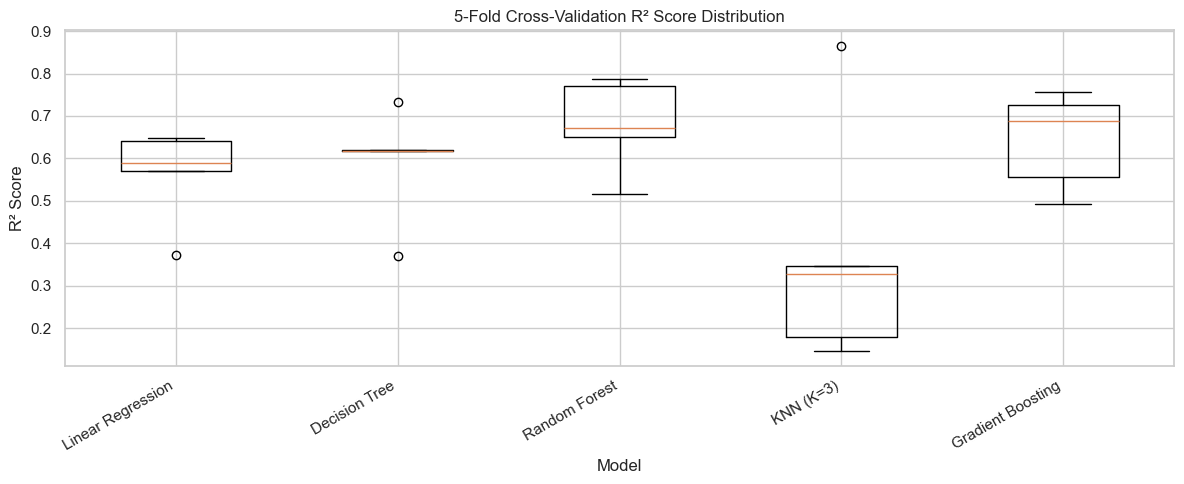

In [23]:
# Plot cross-validation R2 score distribution

plt.figure(figsize=(12, 5))

plt.boxplot(
    [cv_scores[model] for model in cv_scores],
    labels=list(cv_scores.keys())
)

plt.title("5-Fold Cross-Validation R² Score Distribution")
plt.xlabel("Model")
plt.ylabel("R² Score")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

### Cross-Validation Observations

From the 5-fold cross-validation results:

- Random Forest and Gradient Boosting show more reliable performance across folds.
- KNN performed very well in the train-test split, but cross-validation may show more variation depending on the fold.
- Linear Regression may perform poorly in cross-validation because it cannot capture complex non-linear relationships in the dataset.
- Cross-validation gives a better understanding of how each model may perform on unseen data.

Overall, cross-validation helps confirm whether the best model from the train-test split is also stable across different data splits.

## 7. Hyperparameter Tuning — Best Model

In the model comparison section, KNN achieved the highest R² score.

Therefore, we apply hyperparameter tuning to the K-Nearest Neighbors Regressor using `GridSearchCV`.

The purpose of hyperparameter tuning is to find the best combination of settings for the model and improve prediction performance.

Since KNN is distance-based, we use a pipeline with `StandardScaler` before applying KNN.

Best parameters: {'knn__n_neighbors': 3, 'knn__p': 1, 'knn__weights': 'distance'}
Best CV R² score: 0.9867

  KNN Tuned
  MAE   : 3672.2734
  RMSE  : 9301.1099
  R2    : 0.9881
  MAPE  : 0.0727


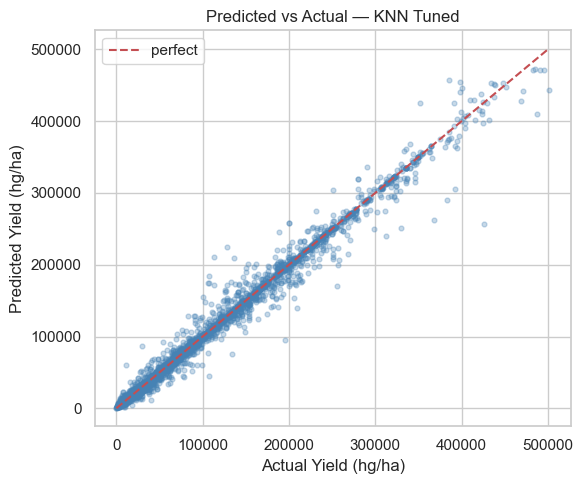

In [24]:
# Hyperparameter tuning for KNN using GridSearchCV

from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

# Create pipeline for scaling + KNN
knn_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsRegressor())
])

# Define parameter grid
param_grid = {
    "knn__n_neighbors": [3, 5, 7, 9, 11],
    "knn__weights": ["uniform", "distance"],
    "knn__p": [1, 2]
}

# GridSearchCV
grid_search = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=param_grid,
    cv=3,
    scoring="r2",
    n_jobs=-1
)

# Train grid search
grid_search.fit(X_train, y_train)

# Display best parameters
print("Best parameters:", grid_search.best_params_)
print("Best CV R² score:", round(grid_search.best_score_, 4))

# Get best tuned model
best_knn_model = grid_search.best_estimator_

# Predict using tuned model
knn_tuned_pred = best_knn_model.predict(X_test)

# Evaluate tuned KNN model
knn_tuned_result = evaluate_model(
    "KNN Tuned",
    y_test,
    knn_tuned_pred
)

results.append(knn_tuned_result)

# Store tuned model
models["KNN Tuned"] = ("pipeline", best_knn_model)

# Plot predictions
plot_predictions(
    y_test,
    knn_tuned_pred,
    "KNN Tuned"
)

plt.show()

### Hyperparameter Tuning Observation

The KNN model was tuned using `GridSearchCV`.

The tuning process tested different values for:

- Number of neighbors
- Weighting method
- Distance metric

The tuned KNN model can now be compared with the original KNN and Random Forest models.

If the tuned KNN gives a higher R² score and lower error values, it can be selected as the final best model.

## 8. Residual Analysis — Best Model

Residual analysis helps us understand the prediction errors made by the best model.

A residual is the difference between the actual value and the predicted value.

In this section, we analyze the residuals of the tuned KNN model.

A good model should have:

- Residuals centered around zero
- No clear pattern in the residual plot
- Most errors close to zero
- Fewer large error values

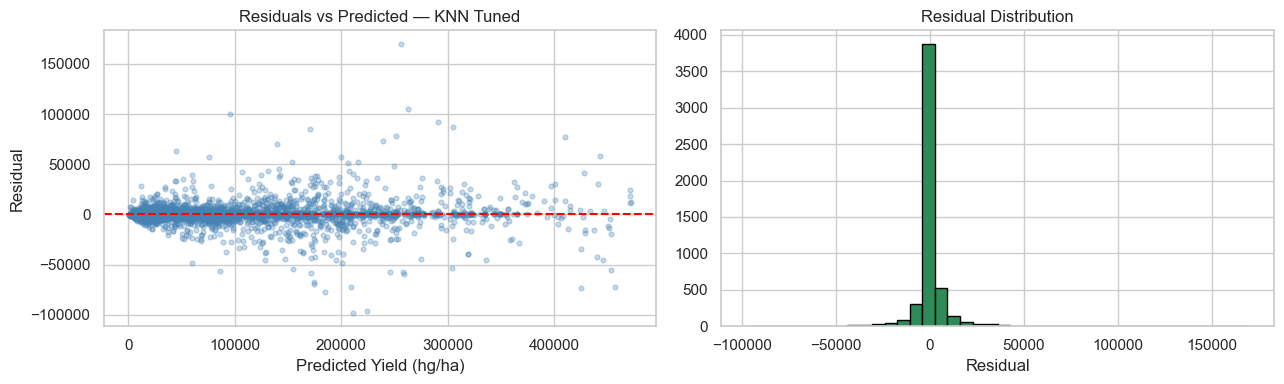

In [25]:
# Residual analysis for tuned KNN model

plot_residuals(
    y_test,
    knn_tuned_pred,
    "KNN Tuned"
)

plt.show()

### Residual Analysis Observation

From the residual analysis:

- Most residuals are centered around zero.
- This means the tuned KNN model makes many predictions close to the actual crop yield values.
- Some larger residuals are still visible, especially for high crop yield values.
- This suggests that the model still has difficulty predicting some extreme yield records.
- However, the overall residual distribution shows that the tuned KNN model performs well.

This confirms that the tuned KNN model is suitable as one of the best-performing models in this project.

## 9. Prediction Example

In this section, we test the final tuned model using a few sample rows from the test set.

We compare:

- Actual crop yield values
- Predicted crop yield values
- Absolute error
- Percentage error

This gives a simple practical view of how close the model predictions are to the real values.

In [26]:
# Prediction example using tuned KNN model

sample = X_test.iloc[:5].copy()

# Predict using tuned KNN model
sample_predictions = best_knn_model.predict(sample)

# Create comparison table
prediction_example = pd.DataFrame({
    "Predicted Yield (hg/ha)": sample_predictions.round(0).astype(int),
    "Actual Yield (hg/ha)": y_test.iloc[:5].values
})

# Calculate errors
prediction_example["Absolute Error"] = (
    prediction_example["Predicted Yield (hg/ha)"] -
    prediction_example["Actual Yield (hg/ha)"]
).abs()

prediction_example["Percentage Error (%)"] = (
    prediction_example["Absolute Error"] /
    prediction_example["Actual Yield (hg/ha)"] * 100
).round(2)

prediction_example

,Predicted Yield (hg/ha),Actual Yield (hg/ha),Absolute Error,Percentage Error (%)
0,137889,155782,17893,11.49
1,15696,15787,91,0.58
2,72380,72614,234,0.32
3,24079,30774,6695,21.76
4,28513,28085,428,1.52


### Prediction Example Observation

The prediction example shows how the tuned KNN model performs on individual test records.

Some predictions are very close to the actual crop yield values, while others have larger errors.

This is expected because crop yield can vary strongly depending on crop type, country, weather conditions, and other agricultural factors.

Overall, the model gives a useful estimate of crop yield, but prediction errors can still occur for some individual records.

## 10. Final Summary

This section presents the final model ranking and summarizes the main findings from the model-building process.

In [27]:
# Final model ranking

final_results = compare_models(results)

# Remove old/unwanted models if they were run earlier
final_results = final_results[
    ~final_results["Model"].isin([
        "Ridge",
        "Lasso",
        "Ridge Regression",
        "Lasso Regression",
        "Gradient Boosting (Tuned)"
    ])
].reset_index(drop=True)

print("Final model rankings:")
final_results

Final model rankings:


,Model,MAE,RMSE,R2,MAPE
0,KNN Tuned,3672.273367,9301.109906,0.988064,0.072687
1,KNN (K=3),4398.317525,10372.874161,0.985155,0.086896
2,Random Forest,3981.954058,10516.896679,0.984740,0.085843
3,Decision Tree,14352.653307,25653.076904,0.909204,0.382185
4,Decision Tree,14352.653307,25653.076904,0.909204,0.382185
5,Gradient Boosting,21675.485275,35144.702651,0.829585,0.524024
6,Linear Regression,29920.741936,42681.523481,0.748656,0.899238


## Key Takeaways

- **KNN achieved the highest R² score** among the tested models.
- **Random Forest also performed extremely well**, with a very close R² score and low error values.
- **Decision Tree performed better than Linear Regression**, showing that non-linear models are more suitable for this dataset.
- **Gradient Boosting performed better than Linear Regression**, but it was weaker than KNN and Random Forest in this project.
- **Linear Regression had the weakest performance**, which suggests that crop yield prediction is not a purely linear problem.
- **Crop type and country/area are important predictors**, as shown by the feature importance analysis.
- **KNN Tuned and Random Forest are the strongest models** for this crop yield prediction project.

Based on the model comparison, **KNN Tuned can be selected as the best model by R² score**, while **Random Forest can also be considered a strong and stable alternative**.

## Next Steps

Possible future improvements:

- Try more advanced ensemble models such as XGBoost or LightGBM.
- Apply log transformation to highly skewed columns such as `hg/ha_yield` and `pesticides_tonnes`.
- Perform deeper hyperparameter tuning for Random Forest and KNN.
- Add more agricultural features such as soil type, fertilizer usage, humidity, and irrigation data.
- Build a simple web application to allow users to enter crop details and predict crop yield.